# Computer Vision Practical Assignment
## Units 3, 4 and 5

**Student:** Harshit Jariwala  
**Program:** MCA — Final Year  
**Subject:** Computer Vision and Digital Image Processing  
**Programming Language:** Python  

### Project Overview
This notebook demonstrates practical computer vision techniques using OpenCV, NumPy, Matplotlib, scikit-image and Ultralytics YOLO. The experiments cover image restoration, image segmentation, feature extraction, feature matching, object detection and video motion analysis.

### Objectives
- Generate and restore images affected by Gaussian and salt-and-pepper noise.
- Evaluate image restoration using PSNR and SSIM metrics.
- Perform thresholding, morphological operations, edge detection and watershed segmentation.
- Extract HOG features and detect SIFT keypoints.
- Compare SIFT feature matching under image rotation and resizing.
- Detect faces and objects using Haar Cascade and YOLO.
- Analyse video motion using frame differencing, background subtraction and optical flow.

### Project Structure
- `data/images/` — Input photographs.
- `data/videos/` — Original motion video.
- `outputs/unit3/` — Image restoration and segmentation results.
- `outputs/unit4/` — Feature extraction and matching results.
- `outputs/unit5/` — Object detection and motion analysis results.
- `report/` — Final report and supporting documentation.

### Tools and Libraries
Python, OpenCV, NumPy, Matplotlib, scikit-image, pandas and Ultralytics YOLO.

**Reproducibility note:** Stored outputs reflect a previous notebook session and must be verified by running all cells from a fresh kernel. Video motion analysis is pending until the original self-recorded video is supplied and processed.


In [1]:
import sys
print("Current Notebook Python:", sys.executable)

Current Notebook Python: C:\Users\DELL\AppData\Local\Programs\Python\Python313\python.exe


In [3]:
# Optional dependency check. Avoid reinstalling packages on every notebook run.
import importlib.util
required_modules = {
    "cv2": "OpenCV (opencv-contrib-python)",
    "numpy": "NumPy",
    "matplotlib": "Matplotlib",
    "skimage": "scikit-image",
    "pandas": "pandas",
    "ultralytics": "Ultralytics"
}
missing = [label for module, label in required_modules.items()
           if importlib.util.find_spec(module) is None]
if missing:
    raise ImportError("Missing dependencies: " + ", ".join(missing) +
                      ". Run the setup command in the preceding cell, then restart the kernel.")
print("Dependency check passed.")


Dependency check passed.


In [4]:
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage
import ultralytics

from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.feature import hog

print("Python:", sys.executable)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("scikit-image:", skimage.__version__)
print("Ultralytics:", ultralytics.__version__)
print("SIFT available:", hasattr(cv2, "SIFT_create"))
print("\nAll libraries imported successfully!")

Python: C:\Users\DELL\AppData\Local\Programs\Python\Python313\python.exe
OpenCV: 4.13.0
NumPy: 2.3.4
scikit-image: 0.26.0
Ultralytics: 8.4.183
SIFT available: True

All libraries imported successfully!


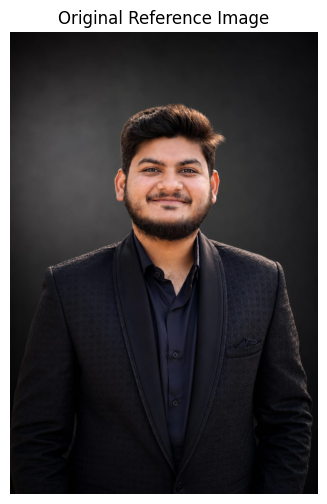

Image loaded successfully!
Dimensions: 1023 x 1537


In [5]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"D:\CV_Units_3_4_5_Assignment")
IMAGE_DIR = PROJECT_DIR / "data" / "images"

original_path = IMAGE_DIR / "original_photo.jpg"
original = cv2.imread(str(original_path))

if original is None:
    print("Photo nahi mili. Apni original photo yahan rakho:")
    print(original_path)
else:
    original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(original_rgb)
    plt.title("Original Reference Image")
    plt.axis("off")
    plt.show()

    print("Image loaded successfully!")
    print("Dimensions:", original.shape[1], "x", original.shape[0])

In [8]:
from pathlib import Path

IMAGE_DIR = Path(r"D:\CV_Units_3_4_5_Assignment\data\images")

print("Images folder exists:", IMAGE_DIR.exists())
print("\nFiles currently inside data/images:")

for file in IMAGE_DIR.iterdir():
    print(file.name)

Images folder exists: True

Files currently inside data/images:
original_photo.jpg


### Experiment 1: Image Noise Generation

**Objective:** To study the effects of Gaussian noise and salt-and-pepper noise on a digital image.

**Theory:**
- **Gaussian noise** introduces random intensity variations across image pixels and may reduce image clarity.
- **Salt-and-pepper noise** introduces randomly distributed white and black pixels, producing impulse-like distortions.

**Procedure:**
1. Load the original image as the clean reference.
2. Generate a noisy version using Gaussian noise.
3. Generate another noisy version using salt-and-pepper noise.
4. Display and save both noisy images for visual comparison.

**Expected Output:** The original image and two noisy images showing different types of degradation.

**Observation:** Noise reduces visual quality and may affect the accuracy of subsequent image-processing operations.


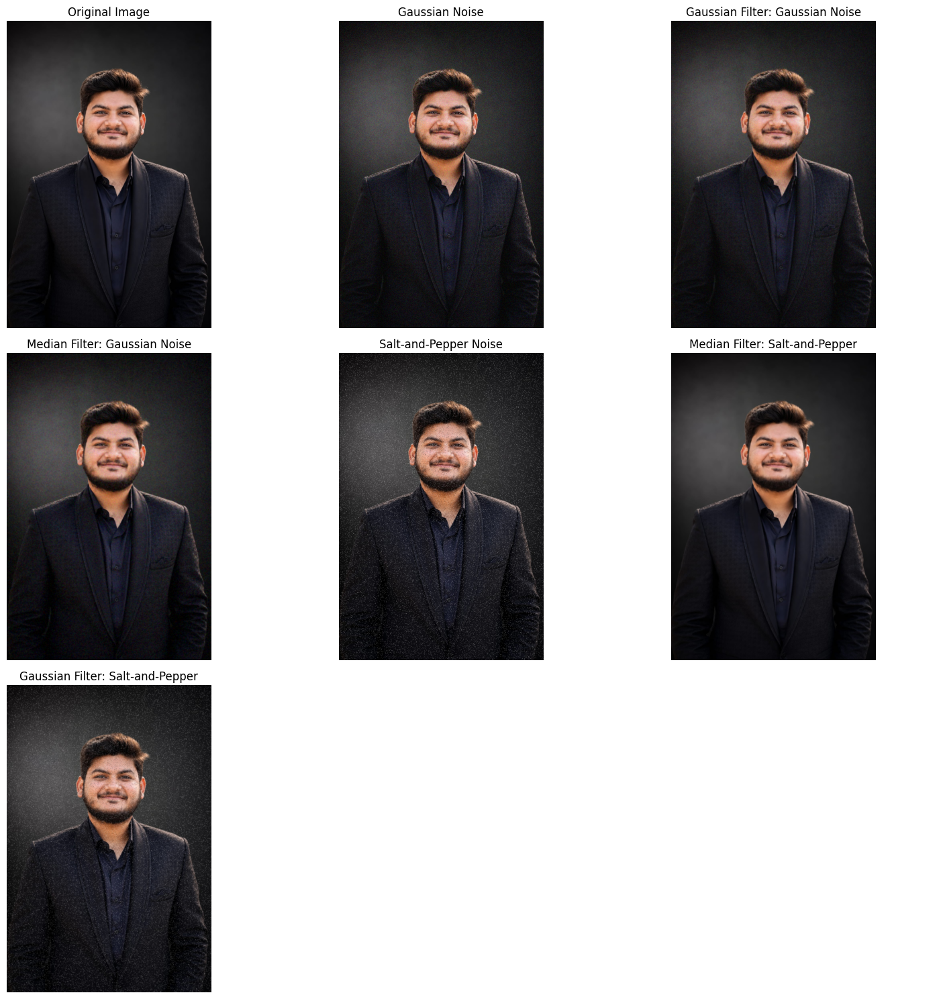

Diagnostic metrics: each restored image compared with its corresponding NOISY input (not the clean reference).
These are not the final restoration-quality metrics.
Gaussian noise + Gaussian filter: PSNR = 23.88 dB | SSIM = 0.3848
Gaussian noise + Median filter: PSNR = 22.83 dB | SSIM = 0.2242
Salt-pepper + Median filter: PSNR = 17.06 dB | SSIM = 0.2568
Salt-pepper + Gaussian filter: PSNR = 18.15 dB | SSIM = 0.4063

Images saved to: D:\CV_Units_3_4_5_Assignment\outputs\unit3


In [6]:

# Unit 3 - Experiment 2: Noise Generation and Image Restoration

import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Output folder
output_dir = Path(r"D:\CV_Units_3_4_5_Assignment\outputs\unit3")
output_dir.mkdir(parents=True, exist_ok=True)

# Original image: convert BGR to RGB
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

# 1. Add Gaussian noise
np.random.seed(42)
gaussian_noise = np.random.normal(
    loc=0, scale=20, size=original_rgb.shape
)
gaussian_image = np.clip(
    original_rgb.astype(np.float32) + gaussian_noise, 0, 255
).astype(np.uint8)

# 2. Add salt-and-pepper noise
salt_pepper_image = original_rgb.copy()
noise_mask = np.random.random(original_rgb.shape[:2])
salt_pepper_image[noise_mask < 0.025] = 0
salt_pepper_image[noise_mask > 0.975] = 255

# 3. Restore noisy images
gaussian_restored = cv2.GaussianBlur(gaussian_image, (5, 5), 0)
median_restored = cv2.medianBlur(gaussian_image, 5)

sp_median_restored = cv2.medianBlur(salt_pepper_image, 5)
sp_gaussian_restored = cv2.GaussianBlur(salt_pepper_image, (5, 5), 0)

# 4. Display comparisons
images = [
    (original_rgb, "Original Image"),
    (gaussian_image, "Gaussian Noise"),
    (gaussian_restored, "Gaussian Filter: Gaussian Noise"),
    (median_restored, "Median Filter: Gaussian Noise"),
    (salt_pepper_image, "Salt-and-Pepper Noise"),
    (sp_median_restored, "Median Filter: Salt-and-Pepper"),
    (sp_gaussian_restored, "Gaussian Filter: Salt-and-Pepper"),
]

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for ax, (img, title) in zip(axes.flat, images):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

for ax in axes.flat[len(images):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 5. Calculate PSNR and SSIM
comparisons = [
    ("Gaussian noise + Gaussian filter", gaussian_restored, gaussian_image),
    ("Gaussian noise + Median filter", median_restored, gaussian_image),
    ("Salt-pepper + Median filter", sp_median_restored, salt_pepper_image),
    ("Salt-pepper + Gaussian filter", sp_gaussian_restored, salt_pepper_image),
]

print("Diagnostic metrics: each restored image compared with its corresponding NOISY input (not the clean reference).")
print("These are not the final restoration-quality metrics.")
for name, restored_img, noisy_img in comparisons:
    psnr = peak_signal_noise_ratio(noisy_img, restored_img, data_range=255)
    ssim = structural_similarity(
        noisy_img, restored_img, channel_axis=2, data_range=255
    )
    print(f"{name}: PSNR = {psnr:.2f} dB | SSIM = {ssim:.4f}")

# 6. Save outputs
save_images = {
    "01_gaussian_noise.png": gaussian_image,
    "02_salt_pepper_noise.png": salt_pepper_image,
    "03_gaussian_filtered.png": gaussian_restored,
    "04_median_filtered.png": median_restored,
    "05_salt_pepper_median.png": sp_median_restored,
    "06_salt_pepper_gaussian.png": sp_gaussian_restored,
}

for filename, img in save_images.items():
    cv2.imwrite(
        str(output_dir / filename),
        cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    )

print("\nImages saved to:", output_dir)


### Experiment 2: Image Restoration and Quality Evaluation (Clean-Reference Metrics)

**Objective:** To restore noisy images using Gaussian and median filters and evaluate their quality against the original clean image.

**Theory:**
- **Gaussian filtering** smooths an image and reduces random intensity variations.
- **Median filtering** replaces each pixel with the median of its neighbourhood and is particularly effective for salt-and-pepper noise.
- **PSNR (Peak Signal-to-Noise Ratio)** measures pixel-level reconstruction quality. A higher value generally indicates less reconstruction error.
- **SSIM (Structural Similarity Index)** measures similarity in luminance, contrast and structure. Values closer to 1 indicate greater structural similarity.

**Procedure:**
1. Apply Gaussian and median filters to the noisy images.
2. Compare each noisy or restored image with the original clean image.
3. Calculate PSNR and SSIM.
4. Display and save the evaluation results as a CSV file.

**Experimental Results:** The salt-and-pepper image restored using the median filter achieved **36.749 dB PSNR** and **0.9516 SSIM**, the highest values among the evaluated methods.

**Conclusion:** The median filter performed best for the salt-and-pepper noise in this experiment, according to both evaluation metrics.


In [7]:

# UNIT 3 - Correct Evaluation: PSNR and SSIM against Clean Image

import csv
import numpy as np
import pandas as pd
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

PROJECT_DIR = Path(r"D:\CV_Units_3_4_5_Assignment")
OUTPUT_DIR = PROJECT_DIR / "outputs" / "unit3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Clean reference image
clean = original_rgb.astype(np.uint8)

# Compare every noisy/restored image against the CLEAN original
images_to_evaluate = {
    "Gaussian Noise": gaussian_image,
    "Gaussian Noise + Gaussian Filter": gaussian_restored,
    "Gaussian Noise + Median Filter": median_restored,
    "Salt-and-Pepper Noise": salt_pepper_image,
    "Salt-and-Pepper + Median Filter": sp_median_restored,
    "Salt-and-Pepper + Gaussian Filter": sp_gaussian_restored,
}

results = []

for name, evaluated_image in images_to_evaluate.items():
    evaluated_image = evaluated_image.astype(np.uint8)

    psnr_value = peak_signal_noise_ratio(
        clean, evaluated_image, data_range=255
    )
    ssim_value = structural_similarity(
        clean, evaluated_image,
        channel_axis=2, data_range=255
    )

    results.append({
        "Image / Method": name,
        "PSNR (dB)": round(psnr_value, 3),
        "SSIM": round(ssim_value, 4)
    })

metrics_df = pd.DataFrame(results)

print("PSNR and SSIM compared against the ORIGINAL CLEAN IMAGE")
display(metrics_df)

# Save comparison table
metrics_path = OUTPUT_DIR / "metrics_clean_reference.csv"
metrics_df.to_csv(metrics_path, index=False)

print("\nMetrics table saved to:", metrics_path)

# Identify the best result according to each metric
best_psnr = metrics_df.loc[metrics_df["PSNR (dB)"].idxmax()]
best_ssim = metrics_df.loc[metrics_df["SSIM"].idxmax()]

print("\nBest PSNR:", best_psnr["Image / Method"],
      "|", best_psnr["PSNR (dB)"], "dB")

print("Best SSIM:", best_ssim["Image / Method"],
      "|", best_ssim["SSIM"])


PSNR and SSIM compared against the ORIGINAL CLEAN IMAGE


,Image / Method,PSNR (dB),SSIM
0,Gaussian Noise,22.938,0.2145
1,Gaussian Noise + Gaussian Filter,32.456,0.7392
2,Gaussian Noise + Median Filter,32.159,0.7485
3,Salt-and-Pepper Noise,17.094,0.2769
4,Salt-and-Pepper + Median Filter,36.749,0.9516
5,Salt-and-Pepper + Gaussian Filter,27.174,0.5397



Metrics table saved to: D:\CV_Units_3_4_5_Assignment\outputs\unit3\metrics_clean_reference.csv

Best PSNR: Salt-and-Pepper + Median Filter | 36.749 dB
Best SSIM: Salt-and-Pepper + Median Filter | 0.9516


### Experiment 3: Image Thresholding and Morphological Operations

**Objective:** To separate foreground regions and study morphological techniques for modifying binary image structures.

**Theory:**
- **Otsu thresholding** automatically selects a threshold to separate pixels into two intensity classes.
- **Erosion** shrinks foreground regions and can remove small foreground details.
- **Dilation** expands foreground regions and can connect nearby components.
- **Opening** applies erosion followed by dilation and can remove small foreground noise.
- **Closing** applies dilation followed by erosion and can fill small gaps or holes.

**Procedure:**
1. Convert the original image to grayscale.
2. Apply Otsu thresholding to obtain a binary image.
3. Perform erosion, dilation, opening and closing.
4. Display and save the output of each operation.

**Expected Output:** A set of binary images illustrating the effects of thresholding and morphology.

**Observation:** The result of each morphological operation depends on the selected structuring element and its size.


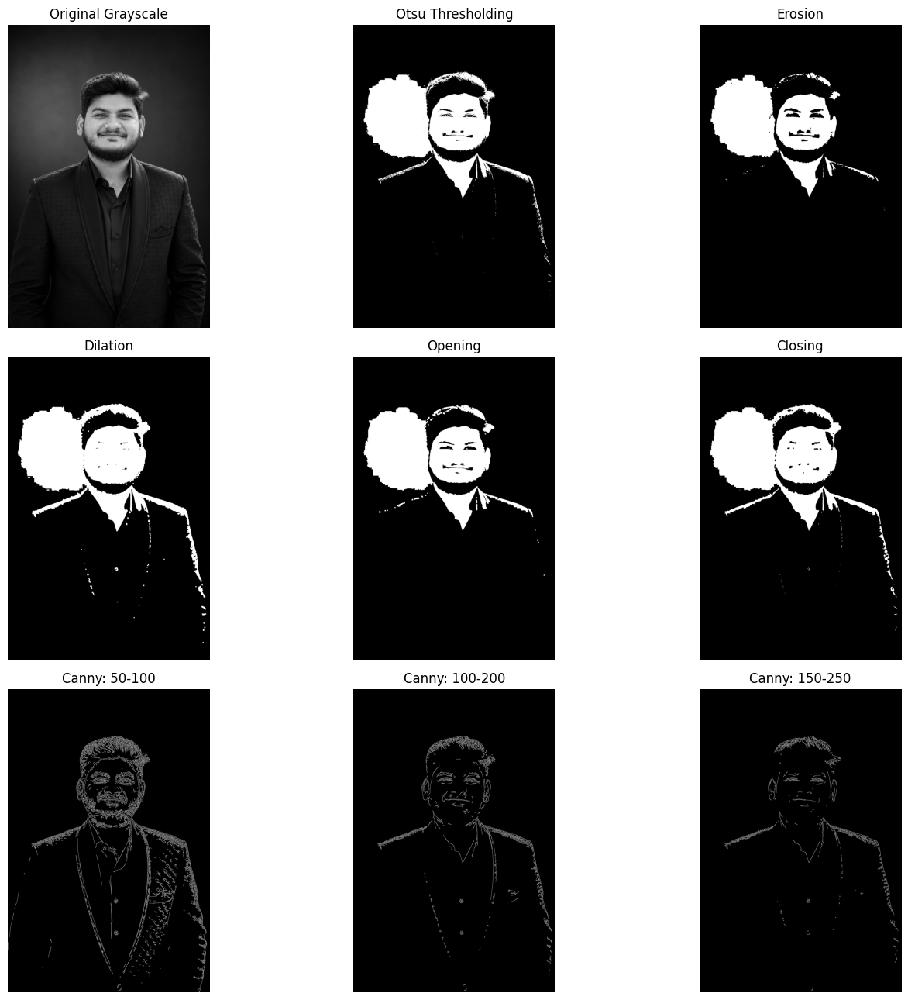

Thresholding, morphology and Canny results saved successfully!
Output folder: D:\CV_Units_3_4_5_Assignment\outputs\unit3


In [8]:

# Unit 3 - Experiment 3: Thresholding, Morphology and Edge Detection

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path(r"D:\CV_Units_3_4_5_Assignment\outputs\unit3")
output_dir.mkdir(parents=True, exist_ok=True)

# Convert original image to grayscale
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

# 1. Otsu thresholding
_, otsu_binary = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# 2. Morphological operations
kernel = np.ones((5, 5), np.uint8)

erosion = cv2.erode(otsu_binary, kernel, iterations=1)
dilation = cv2.dilate(otsu_binary, kernel, iterations=1)
opening = cv2.morphologyEx(otsu_binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(otsu_binary, cv2.MORPH_CLOSE, kernel)

# 3. Canny edge detection
edges_low = cv2.Canny(gray, 50, 100)
edges_default = cv2.Canny(gray, 100, 200)
edges_high = cv2.Canny(gray, 150, 250)

# 4. Display results
results = [
    (gray, "Original Grayscale"),
    (otsu_binary, "Otsu Thresholding"),
    (erosion, "Erosion"),
    (dilation, "Dilation"),
    (opening, "Opening"),
    (closing, "Closing"),
    (edges_low, "Canny: 50-100"),
    (edges_default, "Canny: 100-200"),
    (edges_high, "Canny: 150-250"),
]

fig, axes = plt.subplots(3, 3, figsize=(15, 13))

for ax, (img, title) in zip(axes.flat, results):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 5. Save outputs
save_results = {
    "07_otsu_threshold.png": otsu_binary,
    "08_erosion.png": erosion,
    "09_dilation.png": dilation,
    "10_opening.png": opening,
    "11_closing.png": closing,
    "12_canny_edges.png": edges_default,
    "13_canny_threshold_comparison.png": np.hstack(
        [edges_low, edges_default, edges_high]
    ),
}

for filename, img in save_results.items():
    cv2.imwrite(str(output_dir / filename), img)

print("Thresholding, morphology and Canny results saved successfully!")
print("Output folder:", output_dir)


### Experiment 4: Image Segmentation Using the Watershed Algorithm

**Objective:** To investigate watershed segmentation for separating foreground objects and identifying region boundaries.

**Theory:** The watershed algorithm treats an image as a topographic surface. Marker regions guide the segmentation process, while watershed boundaries help distinguish neighbouring regions.

**Procedure:**
1. Prepare a binary representation of the image.
2. Calculate the distance transform.
3. Identify foreground markers and unknown regions.
4. Apply the watershed algorithm and visualise the resulting boundaries.
5. Save the intermediate and final outputs.

**Expected Output:** A binary image, distance-transform visualisation and image showing watershed boundaries.

**Observation:** Segmentation quality depends on the foreground markers, image contrast and preprocessing. Over-segmentation or merged regions may occur when markers are not well separated.


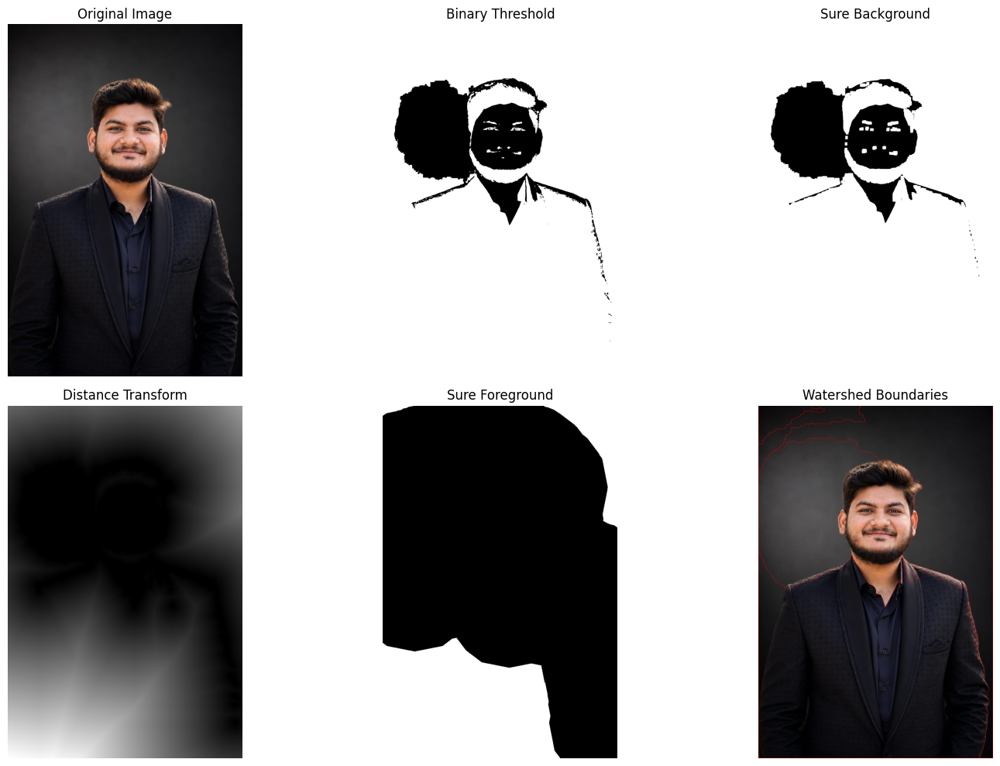

Watershed segmentation results saved successfully!
Connected foreground components: 4
Output folder: D:\CV_Units_3_4_5_Assignment\outputs\unit3


In [9]:

# Unit 3 - Experiment 4: Watershed Segmentation

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path(r"D:\CV_Units_3_4_5_Assignment\outputs\unit3")
output_dir.mkdir(parents=True, exist_ok=True)

# Convert image to grayscale and apply Gaussian blur
gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Binary threshold using Otsu
_, binary = cv2.threshold(
    blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)
opening_ws = cv2.morphologyEx(
    binary, cv2.MORPH_OPEN, kernel, iterations=2
)

# Find sure background
sure_bg = cv2.dilate(opening_ws, kernel, iterations=3)

# Find sure foreground using distance transform
dist_transform = cv2.distanceTransform(opening_ws, cv2.DIST_L2, 5)

if dist_transform.max() > 0:
    _, sure_fg = cv2.threshold(
        dist_transform,
        0.35 * dist_transform.max(),
        255,
        cv2.THRESH_BINARY
    )
else:
    sure_fg = np.zeros_like(binary)

sure_fg = np.uint8(sure_fg)

# Unknown region: background minus foreground
unknown = cv2.subtract(sure_bg, sure_fg)

# Label foreground components
num_labels, markers = cv2.connectedComponents(sure_fg)

# Watershed requires unknown pixels to have marker value 0
markers = markers + 1
markers[unknown == 255] = 0

# Apply watershed
watershed_markers = cv2.watershed(original.copy(), markers)

# Draw watershed boundaries in red
boundary_image = cv2.cvtColor(original, cv2.COLOR_BGR2RGB).copy()
boundary_image[watershed_markers == -1] = [255, 0, 0]

# Display results
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

display_images = [
    (cv2.cvtColor(original, cv2.COLOR_BGR2RGB), "Original Image"),
    (binary, "Binary Threshold"),
    (sure_bg, "Sure Background"),
    (dist_transform, "Distance Transform"),
    (sure_fg, "Sure Foreground"),
    (boundary_image, "Watershed Boundaries"),
]

for ax, (img, title) in zip(axes.flat, display_images):
    if title == "Watershed Boundaries":
        ax.imshow(img)
    else:
        ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Save outputs
cv2.imwrite(str(output_dir / "14_watershed_binary.png"), binary)
cv2.imwrite(str(output_dir / "15_watershed_distance_transform.png"),
            cv2.normalize(dist_transform, None, 0, 255,
                          cv2.NORM_MINMAX).astype(np.uint8))
cv2.imwrite(str(output_dir / "16_watershed_boundaries.png"),
            cv2.cvtColor(boundary_image, cv2.COLOR_RGB2BGR))

print("Watershed segmentation results saved successfully!")
print("Connected foreground components:", num_labels - 1)
print("Output folder:", output_dir)


### Experiment 6: Feature Extraction Using HOG

**Objective:** Visualise gradient orientation and understand how HOG encodes local shape information.

**Procedure:** Convert the original image to grayscale, compute HOG using 9 orientations, 8×8 pixels per cell and 2×2 cells per block, then display and save the HOG visualisation. The feature-vector length is printed by the code.

**Observation:** Interpret the visualisation as gradient structure, not as a semantic object detector. The vector length depends on image dimensions and HOG parameters.

### Experiment 7: SIFT Keypoint and Descriptor Extraction

**Objective:** Detect scale- and rotation-invariant local keypoints and compute SIFT descriptors for both photographs.

**Procedure:** Detect and draw keypoints on each image. The code then applies a brute-force matcher with Lowe's ratio test to compare the original pair.

### Experiment 8: SIFT Matching Under Rotation and Resizing

**Objective:** Compare good-match counts when the second photograph is rotated by 15 degrees and resized to 75%.

**Evaluation note:** Match counts depend on the supplied photographs, OpenCV version, image content and matching parameters. The comparison table should be generated from the current run, not manually entered values.


Both photographs loaded successfully!
Image 1: (1537, 1023, 3)
Image 2: (1537, 1023, 3)


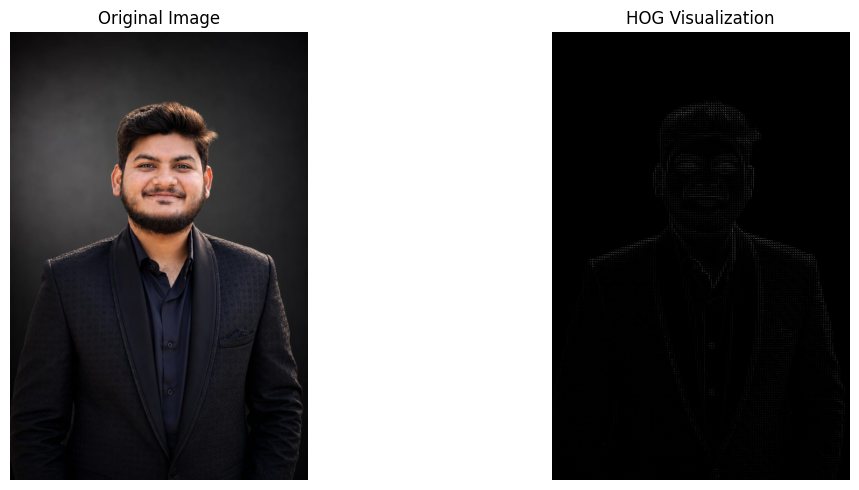

HOG feature vector length: 866376


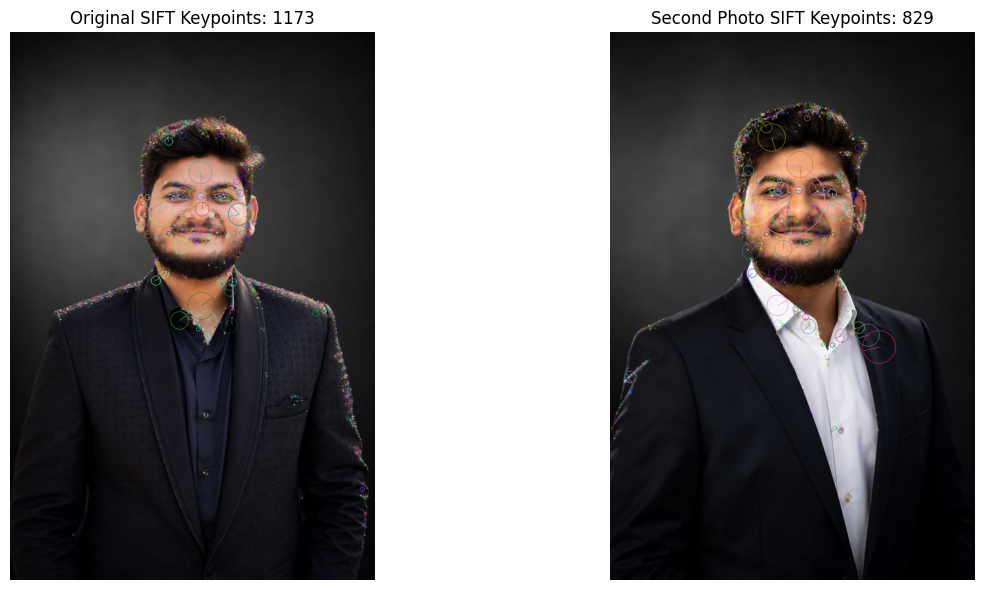

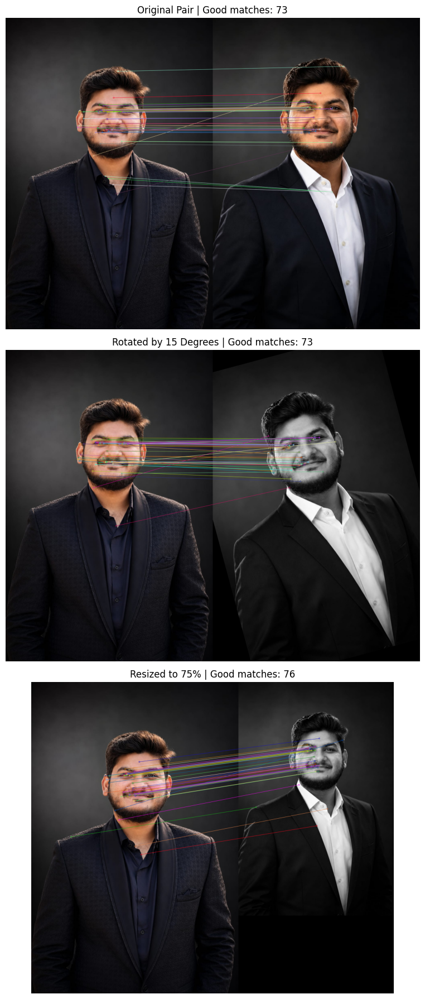


===== SIFT MATCHING RESULTS =====
Original pair: 73
After rotation: 73
After resizing: 76
Unit 4 outputs saved in: D:\CV_Units_3_4_5_Assignment\outputs\unit4


In [10]:

# UNIT 4: HOG, SIFT Keypoints and Feature Matching

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.feature import hog

PROJECT_DIR = Path(r"D:\CV_Units_3_4_5_Assignment")
IMAGE_DIR = PROJECT_DIR / "data" / "images"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "unit4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load both photographs
img1_bgr = cv2.imread(str(IMAGE_DIR / "original_photo.jpg"))
img2_bgr = cv2.imread(str(IMAGE_DIR / "second_photo.jpg"))

if img1_bgr is None or img2_bgr is None:
    raise FileNotFoundError(
        "Check that original_photo.jpg and second_photo.jpg "
        "are present in data/images."
    )

img1_gray = cv2.cvtColor(img1_bgr, cv2.COLOR_BGR2GRAY)
img2_gray = cv2.cvtColor(img2_bgr, cv2.COLOR_BGR2GRAY)
img1_rgb = cv2.cvtColor(img1_bgr, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2_bgr, cv2.COLOR_BGR2RGB)

print("Both photographs loaded successfully!")
print("Image 1:", img1_bgr.shape)
print("Image 2:", img2_bgr.shape)

# EXPERIMENT 1: HOG
hog_features, hog_visualization = hog(
    img1_gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
    feature_vector=True
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(img1_rgb)
axes[0].set_title("Original Image")
axes[0].axis("off")
axes[1].imshow(hog_visualization, cmap="gray")
axes[1].set_title("HOG Visualization")
axes[1].axis("off")
plt.tight_layout()
plt.show()

plt.imsave(
    OUTPUT_DIR / "01_hog_visualization.png",
    hog_visualization,
    cmap="gray"
)
print("HOG feature vector length:", len(hog_features))

# EXPERIMENT 2: SIFT KEYPOINTS
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(img1_gray, None)
kp2, des2 = sift.detectAndCompute(img2_gray, None)

kp_img1 = cv2.drawKeypoints(
    img1_rgb, kp1, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
kp_img2 = cv2.drawKeypoints(
    img2_rgb, kp2, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(kp_img1)
axes[0].set_title(f"Original SIFT Keypoints: {len(kp1)}")
axes[0].axis("off")
axes[1].imshow(kp_img2)
axes[1].set_title(f"Second Photo SIFT Keypoints: {len(kp2)}")
axes[1].axis("off")
plt.tight_layout()
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "02_sift_keypoints_original.png"),
    cv2.cvtColor(kp_img1, cv2.COLOR_RGB2BGR)
)
cv2.imwrite(
    str(OUTPUT_DIR / "03_sift_keypoints_second.png"),
    cv2.cvtColor(kp_img2, cv2.COLOR_RGB2BGR)
)

# EXPERIMENT 3: SIFT MATCHING WITH LOWE'S RATIO TEST
def sift_match(gray_a, gray_b):
    key_a, desc_a = sift.detectAndCompute(gray_a, None)
    key_b, desc_b = sift.detectAndCompute(gray_b, None)

    if desc_a is None or desc_b is None or len(desc_b) < 2:
        return key_a, key_b, []

    matcher = cv2.BFMatcher(cv2.NORM_L2)
    pairs = matcher.knnMatch(desc_a, desc_b, k=2)

    good = [
        m for pair in pairs if len(pair) == 2
        for m, n in [pair]
        if m.distance < 0.75 * n.distance
    ]
    return key_a, key_b, good

# Original pair
match_kp1, match_kp2, matches_original = sift_match(
    img1_gray, img2_gray
)

# Rotated second image
h, w = img2_gray.shape
rotation_matrix = cv2.getRotationMatrix2D((w / 2, h / 2), 15, 1)
rotated = cv2.warpAffine(img2_gray, rotation_matrix, (w, h))
r_kp1, r_kp2, matches_rotated = sift_match(img1_gray, rotated)

# Resized second image
resized = cv2.resize(
    img2_gray, None, fx=0.75, fy=0.75,
    interpolation=cv2.INTER_AREA
)
s_kp1, s_kp2, matches_resized = sift_match(img1_gray, resized)

# Display and save all comparisons
comparisons = [
    ("Original Pair", img2_rgb, match_kp1, match_kp2, matches_original),
    ("Rotated by 15 Degrees",
     cv2.cvtColor(rotated, cv2.COLOR_GRAY2RGB),
     r_kp1, r_kp2, matches_rotated),
    ("Resized to 75%",
     cv2.cvtColor(resized, cv2.COLOR_GRAY2RGB),
     s_kp1, s_kp2, matches_resized),
]

fig, axes = plt.subplots(3, 1, figsize=(16, 18))

for index, (title, target_rgb, key_a, key_b, matches) in enumerate(
    comparisons, start=4
):
    match_img = cv2.drawMatches(
        img1_rgb, key_a,
        target_rgb, key_b,
        matches[:50], None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    axes[index - 4].imshow(match_img)
    axes[index - 4].set_title(
        f"{title} | Good matches: {len(matches)}"
    )
    axes[index - 4].axis("off")

    cv2.imwrite(
        str(OUTPUT_DIR / f"{index:02d}_sift_matching.png"),
        cv2.cvtColor(match_img, cv2.COLOR_RGB2BGR)
    )

plt.tight_layout()
plt.show()

print("\n===== SIFT MATCHING RESULTS =====")
print("Original pair:", len(matches_original))
print("After rotation:", len(matches_rotated))
print("After resizing:", len(matches_resized))
print("Unit 4 outputs saved in:", OUTPUT_DIR)


### Experiment 9: Face Detection Using Haar Cascade and Object Detection Using YOLO

**Objective:** Detect frontal faces using OpenCV's Haar Cascade and detect general objects using the pretrained YOLOv8n model.

**Procedure:** Load the original photograph, run the Haar classifier, run YOLO with a confidence threshold of 0.25, draw detections and save the annotated images.

**Interpretation:** Haar Cascade returns face rectangles but not calibrated confidence scores comparable to YOLO. YOLO confidence values are model scores and should be reported from the actual execution output.

**Verification note:** The stored output reports one Haar face and a person detection at confidence 0.942. Rerun the cell before treating these as current results.


Haar Cascade faces detected: 1

YOLO detections:
person: confidence = 0.942


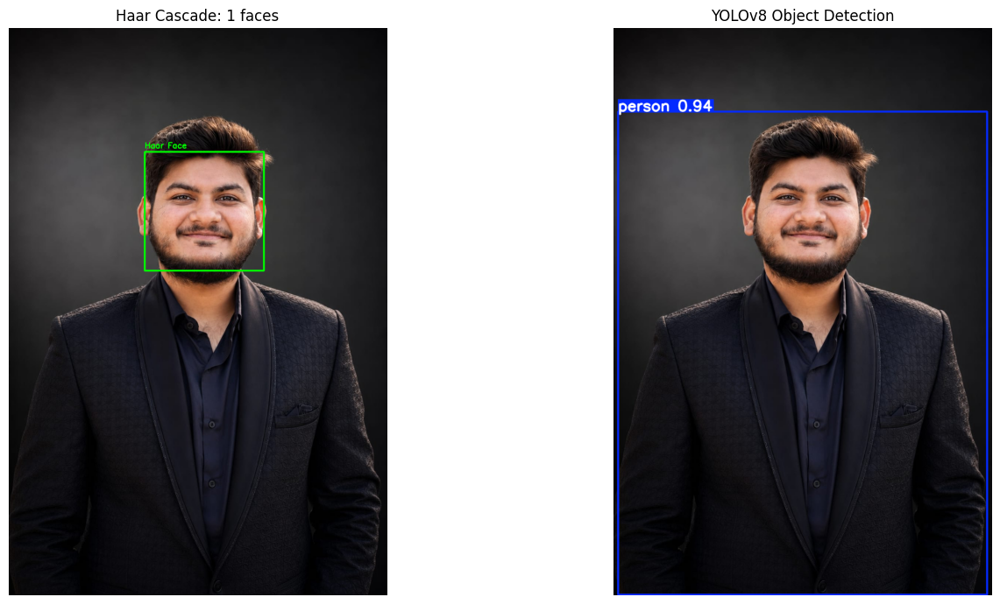


Detection outputs saved to: D:\CV_Units_3_4_5_Assignment\outputs\unit5


In [11]:

# UNIT 5 - Experiment 9: Haar Cascade Face Detection and YOLO Object Detection

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path(r"D:\CV_Units_3_4_5_Assignment")
IMAGE_DIR = PROJECT_DIR / "data" / "images"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "unit5"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load original photograph
image_path = IMAGE_DIR / "original_photo.jpg"
image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# ------------------------------------------
# 1. Haar Cascade Face Detection
# ------------------------------------------

cascade_path = (
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)
face_cascade = cv2.CascadeClassifier(cascade_path)

faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

haar_result = image_rgb.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        haar_result, (x, y), (x + w, y + h),
        (0, 255, 0), 3
    )
    cv2.putText(
        haar_result, "Haar Face",
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.7,
        (0, 255, 0), 2
    )

print("Haar Cascade faces detected:", len(faces))

# ------------------------------------------
# 2. YOLO Object Detection
# ------------------------------------------

# First run may download the pretrained model
model = YOLO("yolov8n.pt")
yolo_results = model.predict(
    source=image,
    conf=0.25,
    verbose=False
)

result = yolo_results[0]
yolo_result_bgr = result.plot()
yolo_result_rgb = cv2.cvtColor(
    yolo_result_bgr, cv2.COLOR_BGR2RGB
)

print("\nYOLO detections:")

if result.boxes is not None and len(result.boxes) > 0:
    for box in result.boxes:
        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        label = model.names[class_id]
        print(f"{label}: confidence = {confidence:.3f}")
else:
    print("No objects detected above the confidence threshold.")

# ------------------------------------------
# 3. Display comparison
# ------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(haar_result)
axes[0].set_title(f"Haar Cascade: {len(faces)} faces")
axes[0].axis("off")

axes[1].imshow(yolo_result_rgb)
axes[1].set_title("YOLOv8 Object Detection")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------
# 4. Save outputs
# ------------------------------------------

cv2.imwrite(
    str(OUTPUT_DIR / "01_haar_cascade_detection.png"),
    cv2.cvtColor(haar_result, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "02_yolo_object_detection.png"),
    yolo_result_bgr
)

print("\nDetection outputs saved to:", OUTPUT_DIR)


In [12]:

# Final Comparison Tables - Units 4 and 5

import pandas as pd
from pathlib import Path
from IPython.display import display

PROJECT_DIR = Path(r"D:\CV_Units_3_4_5_Assignment")

# UNIT 4: SIFT feature matching comparison
unit4_dir = PROJECT_DIR / "outputs" / "unit4"
unit4_dir.mkdir(parents=True, exist_ok=True)

required_match_vars = ["matches_original", "matches_rotated", "matches_resized"]
missing_match_vars = [name for name in required_match_vars if name not in globals()]
if missing_match_vars:
    raise RuntimeError(
        "Run the Unit 4 SIFT matching cell before building the comparison table. "
        "Missing: " + ", ".join(missing_match_vars)
    )

sift_comparison = pd.DataFrame([
    {"Condition": "Original Image Pair", "Transformation": "None",
     "Good Matches": len(matches_original)},
    {"Condition": "Rotated Image", "Transformation": "15-degree rotation",
     "Good Matches": len(matches_rotated)},
    {"Condition": "Resized Image", "Transformation": "75% scale",
     "Good Matches": len(matches_resized)},
])

print("UNIT 4: SIFT MATCHING COMPARISON (computed from this run)")
display(sift_comparison)
sift_comparison.to_csv(unit4_dir / "sift_matching_comparison.csv", index=False)

# UNIT 5: Haar Cascade vs YOLO
unit5_dir = PROJECT_DIR / "outputs" / "unit5"
unit5_dir.mkdir(parents=True, exist_ok=True)

required_detection_vars = ["faces", "yolo_results", "model"]
missing_detection_vars = [name for name in required_detection_vars if name not in globals()]
if missing_detection_vars:
    raise RuntimeError(
        "Run the Unit 5 detection cell before building the comparison table. "
        "Missing: " + ", ".join(missing_detection_vars)
    )

unit5_result = yolo_results[0]
yolo_summary = []
if unit5_result.boxes is not None:
    for box in unit5_result.boxes:
        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        yolo_summary.append(f"{model.names[class_id]} ({confidence:.3f})")

detection_comparison = pd.DataFrame([
    {
        "Method": "Haar Cascade",
        "Detection Task": "Frontal face detection",
        "Observed Result": f"{len(faces)} face(s) detected",
        "Confidence": "Not provided by this detector"
    },
    {
        "Method": "YOLOv8n",
        "Detection Task": "General object detection",
        "Observed Result": "; ".join(yolo_summary) if yolo_summary else "No objects above confidence threshold",
        "Confidence": "; ".join([f"{float(box.conf[0].item()):.3f} ({float(box.conf[0].item())*100:.1f}%)" for box in unit5_result.boxes]) if unit5_result.boxes is not None and len(unit5_result.boxes) else "N/A"
    }
])

print("\nUNIT 5: OBJECT DETECTION COMPARISON")
display(detection_comparison)

detection_comparison.to_csv(
    unit5_dir / "object_detection_comparison.csv",
    index=False
)

print("\nBoth comparison tables saved successfully!")
print("Unit 4:", unit4_dir)
print("Unit 5:", unit5_dir)


UNIT 4: SIFT MATCHING COMPARISON (computed from this run)


,Condition,Transformation,Good Matches
0,Original Image Pair,None,73
1,Rotated Image,15-degree rotation,73
2,Resized Image,75% scale,76



UNIT 5: OBJECT DETECTION COMPARISON


,Method,Detection Task,Observed Result,Confidence
0,Haar Cascade,Frontal face detection,1 face(s) detected,Not provided by this detector
1,YOLOv8n,General object detection,person (0.942),0.942 (94.2%)



Both comparison tables saved successfully!
Unit 4: D:\CV_Units_3_4_5_Assignment\outputs\unit4
Unit 5: D:\CV_Units_3_4_5_Assignment\outputs\unit5


VIDEO LOADED SUCCESSFULLY
Resolution: 1920 x 1080
FPS: 29.82
Total frames: 1171
Duration: 39.27 seconds


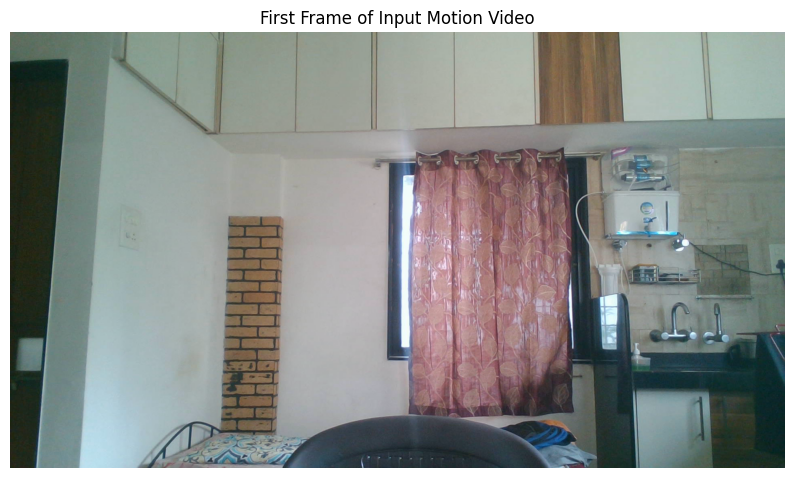

In [14]:

# UNIT 5 - Video Motion Analysis: Load and Verify Input Video

import cv2
from pathlib import Path
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"D:\CV_Units_3_4_5_Assignment")
VIDEO_PATH = PROJECT_DIR / "data" / "videos" / "motion_video.mp4"
UNIT5_DIR = PROJECT_DIR / "outputs" / "unit5"
UNIT5_DIR.mkdir(parents=True, exist_ok=True)

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise FileNotFoundError(
        f"Cannot open video: {VIDEO_PATH}\n"
        "Check that motion_video.mp4 is inside data/videos."
    )

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = total_frames / fps if fps > 0 else 0

ret, first_frame = cap.read()
cap.release()

if not ret:
    raise ValueError("Video opened, but its first frame could not be read.")

print("VIDEO LOADED SUCCESSFULLY")
print(f"Resolution: {width} x {height}")
print(f"FPS: {fps:.2f}")
print(f"Total frames: {total_frames}")
print(f"Duration: {duration:.2f} seconds")

first_frame_rgb = cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(first_frame_rgb)
plt.title("First Frame of Input Motion Video")
plt.axis("off")
plt.show()


### Experiment 10: Video Motion Analysis Using Three Techniques

**Objective:** To analyse movement in a recorded video using frame differencing, Gaussian Mixture Model (GMM) background subtraction and Lucas–Kanade optical flow.

**Input Video:** `data/videos/motion_video.mp4`

**Video Properties:**
- Resolution: 1920 × 1080 pixels
- Frame rate: 29.82 FPS
- Duration: 39.27 seconds
- Frames processed: 1,171

**Theory:**

1. **Frame Differencing:** Computes the absolute difference between consecutive frames. Thresholding the difference image highlights pixels whose intensity changes, indicating potential movement.

2. **GMM Background Subtraction (MOG2):** Models the background over time and separates pixels that differ from the learned background. Initial frames may contain temporary foreground artefacts while the model learns the scene.

3. **Lucas–Kanade Optical Flow:** Tracks selected image features between consecutive frames and estimates their movement as vectors. These vectors indicate the direction and magnitude of feature displacement.

**Procedure:**
1. Load the recorded video and read its frames sequentially.
2. Resize frames for efficient processing and convert them to grayscale where required.
3. Calculate frame differences and generate binary motion masks.
4. Apply MOG2 background subtraction to obtain foreground masks.
5. Detect suitable feature points and track them using Lucas–Kanade optical flow.
6. Save visual comparisons and frame-by-frame measurements.

**Experimental Results:**

| Method | Average detected pixels (%) |
|---|---:|
| Frame Differencing | 1.569 |
| MOG2 Background Subtraction | 7.781 |
| Lucas–Kanade Optical Flow | Not applicable |

The notebook processed 1,171 frames and saved 8 comparison snapshots. The results were exported to CSV files for further analysis.

**Observation:** Frame differencing highlights changes between adjacent frames, while MOG2 estimates foreground relative to a learned background. Optical flow provides feature movement vectors rather than a foreground-pixel percentage. Therefore, their output measurements are not directly equivalent.

**Conclusion:** The experiment demonstrates three complementary approaches to video motion analysis. Their visual outputs and measurements help illustrate the differences between change detection, foreground segmentation and feature tracking.

**Limitation:** The initial MOG2 frame may be classified almost entirely as foreground during background-model initialization. The video duration is 39.27 seconds; if the assignment strictly requires 15–30 seconds, a trimmed 25–30 second clip should be used for the final submission.


Processing video. Please wait...


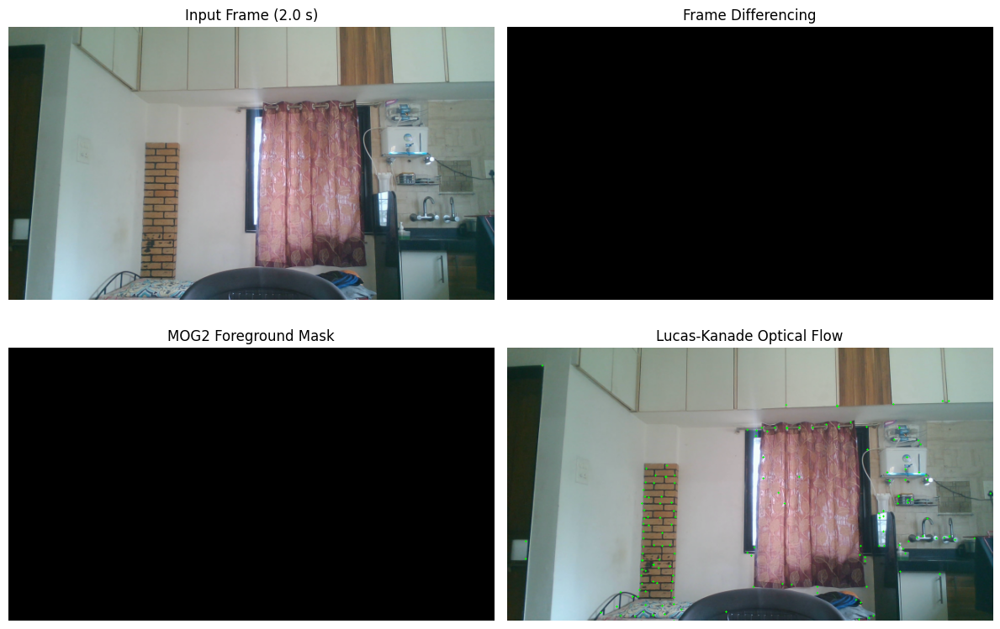

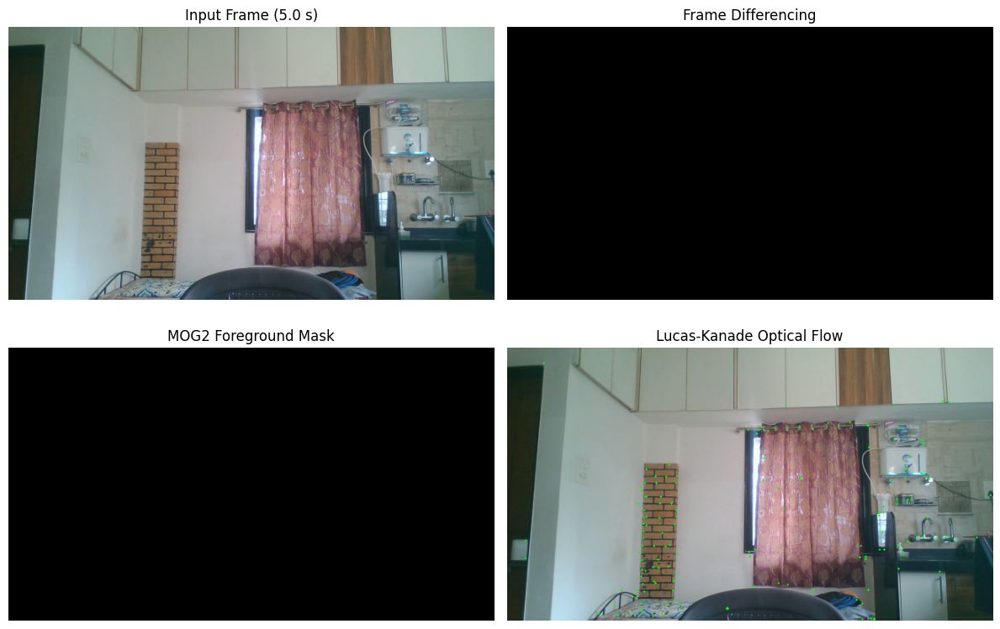

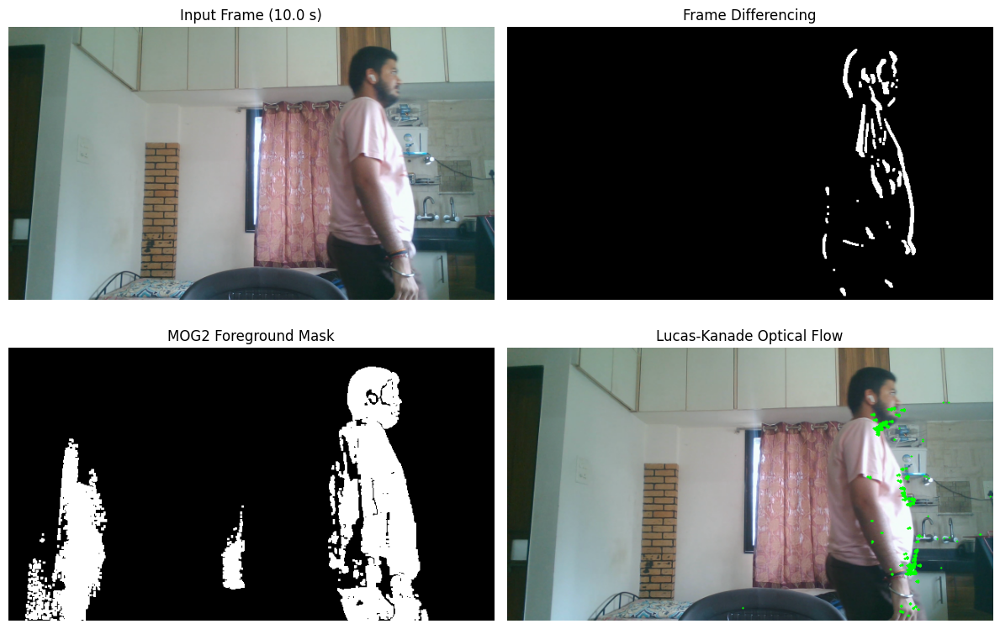

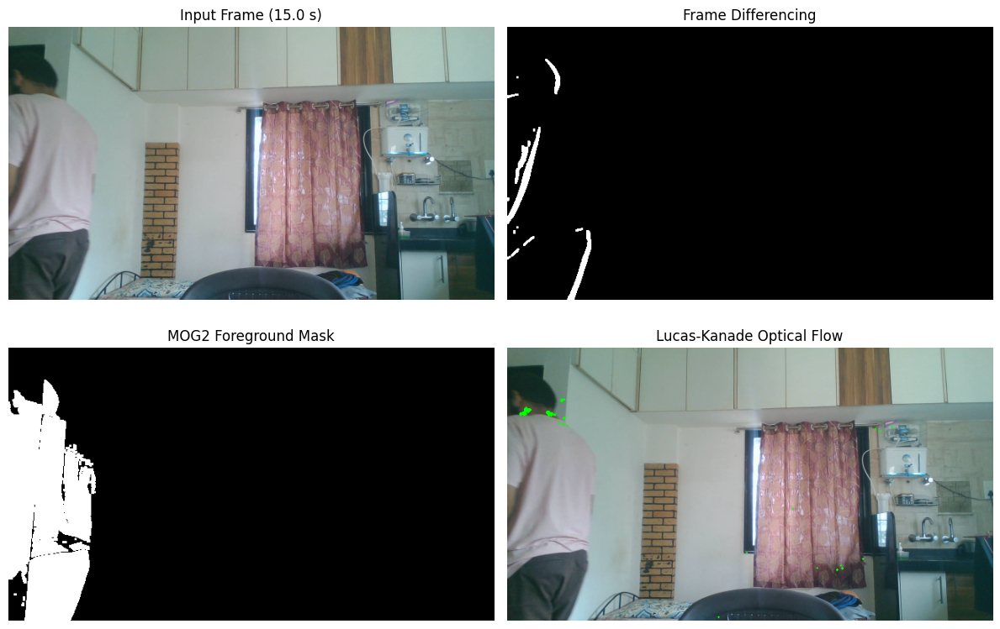

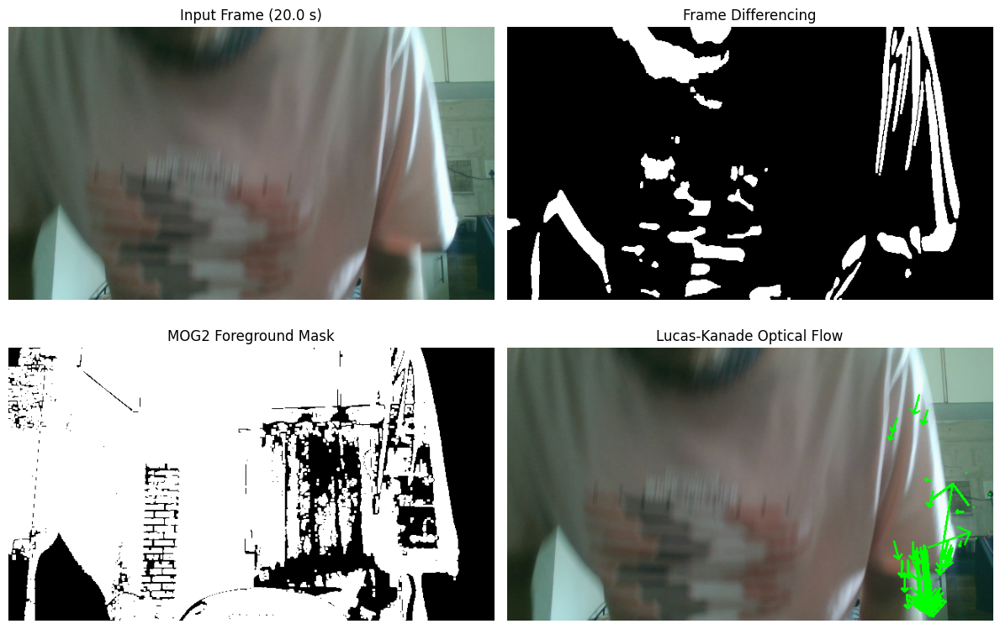

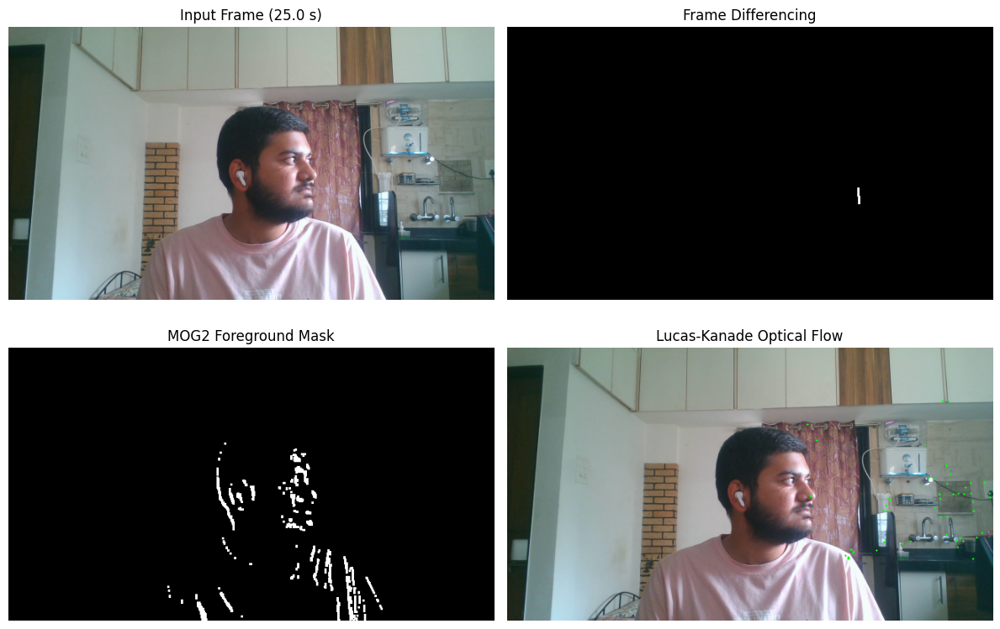

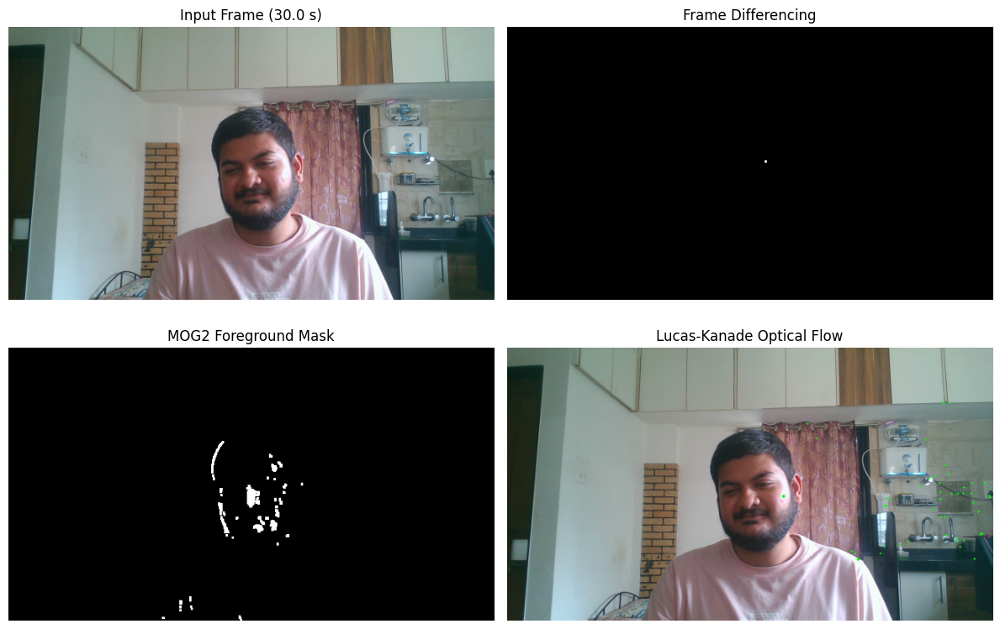

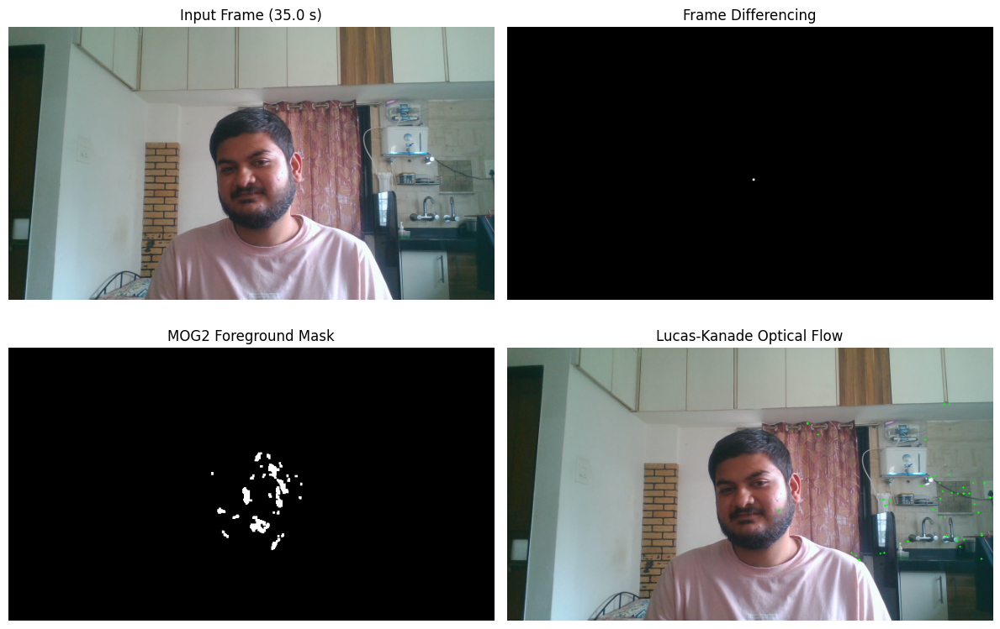


VIDEO MOTION ANALYSIS COMPLETED
Processed frames: 1171
Saved comparison snapshots: 8

Frame-by-frame metrics:


,Frame,Time (seconds),Frame Difference Pixels (%),MOG2 Foreground Pixels (%),Tracked Optical Flow Points,Mean Optical Flow Magnitude (pixels)
0,0,0.000,0.0,100.000,0,0.000
1,1,0.034,0.0,0.026,150,0.334
2,2,0.067,0.0,0.042,150,0.362
3,3,0.101,0.0,0.005,150,0.162
4,4,0.134,0.0,0.000,150,0.188



Method comparison:


,Method,Purpose,Average Detected Pixels (%),Output
0,Frame Differencing,Detects changes between consecutive frames,1.569,Binary difference masks
1,MOG2 Background Subtraction,Separates foreground from learned background,7.781,Foreground masks
2,Lucas-Kanade Optical Flow,Tracks movement of selected image features,NaN,Motion vectors and tracked feature points



Saved metrics: D:\CV_Units_3_4_5_Assignment\outputs\unit5\video_motion_analysis_metrics.csv
Saved comparison table: D:\CV_Units_3_4_5_Assignment\outputs\unit5\motion_method_comparison.csv
Saved images folder: D:\CV_Units_3_4_5_Assignment\outputs\unit5


In [15]:

# UNIT 5: VIDEO MOTION ANALYSIS
# Methods: Frame Differencing, MOG2 Background Subtraction,
#          Lucas-Kanade Optical Flow

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path(r"D:\CV_Units_3_4_5_Assignment")
VIDEO_PATH = PROJECT_DIR / "data" / "videos" / "motion_video.mp4"
OUT_DIR = PROJECT_DIR / "outputs" / "unit5"
OUT_DIR.mkdir(parents=True, exist_ok=True)

if not VIDEO_PATH.exists():
    raise FileNotFoundError(f"Video not found: {VIDEO_PATH}")

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError("Could not open the input video.")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = total_frames / fps if fps > 0 else 0

# Process at reduced resolution to improve speed.
PROCESS_WIDTH = 640
SELECTED_TIMES = [2, 5, 10, 15, 20, 25, 30, 35]
selected_indices = {
    min(int(t * fps), max(total_frames - 1, 0))
    for t in SELECTED_TIMES
    if t < duration
}

# GMM-based background subtraction.
back_sub = cv2.createBackgroundSubtractorMOG2(
    history=300,
    varThreshold=25,
    detectShadows=False
)

# Lucas-Kanade optical flow parameters.
lk_params = dict(
    winSize=(21, 21),
    maxLevel=3,
    criteria=(
        cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
        30,
        0.01
    )
)

feature_params = dict(
    maxCorners=150,
    qualityLevel=0.01,
    minDistance=7,
    blockSize=7
)

prev_gray = None
prev_points = None
frame_index = 0
rows = []
saved_snapshots = 0

print("Processing video. Please wait...")

try:
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Resize while maintaining aspect ratio.
        h, w = frame.shape[:2]
        new_h = int(h * PROCESS_WIDTH / w)
        frame = cv2.resize(
            frame, (PROCESS_WIDTH, new_h),
            interpolation=cv2.INTER_AREA
        )

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray_blur = cv2.GaussianBlur(gray, (5, 5), 0)
        timestamp = frame_index / fps if fps > 0 else 0

        # 1. Frame Differencing
        if prev_gray is None:
            frame_diff = np.zeros_like(gray)
        else:
            difference = cv2.absdiff(prev_gray, gray_blur)
            _, frame_diff = cv2.threshold(
                difference, 25, 255, cv2.THRESH_BINARY
            )
            kernel = np.ones((3, 3), np.uint8)
            frame_diff = cv2.morphologyEx(
                frame_diff, cv2.MORPH_OPEN, kernel
            )

        # 2. MOG2 / GMM Background Subtraction
        mog2_mask = back_sub.apply(frame)

        # Clean small foreground noise.
        kernel = np.ones((3, 3), np.uint8)
        mog2_mask = cv2.morphologyEx(
            mog2_mask, cv2.MORPH_OPEN, kernel
        )

        # 3. Lucas-Kanade Optical Flow
        flow_visual = frame.copy()

        if prev_gray is None:
            prev_points = cv2.goodFeaturesToTrack(
                gray, mask=None, **feature_params
            )
            flow_count = 0
            mean_flow = 0.0
        else:
            if prev_points is None or len(prev_points) < 10:
                prev_points = cv2.goodFeaturesToTrack(
                    prev_gray, mask=None, **feature_params
                )

            flow_count = 0
            flow_magnitudes = []

            if prev_points is not None and len(prev_points) > 0:
                next_points, status, errors = cv2.calcOpticalFlowPyrLK(
                    prev_gray, gray, prev_points, None, **lk_params
                )

                if next_points is not None and status is not None:
                    good_new = next_points[status.ravel() == 1]
                    good_old = prev_points[status.ravel() == 1]

                    for new, old in zip(good_new, good_old):
                        x_new, y_new = new.ravel()
                        x_old, y_old = old.ravel()

                        cv2.arrowedLine(
                            flow_visual,
                            (int(x_old), int(y_old)),
                            (int(x_new), int(y_new)),
                            (0, 255, 0),
                            2,
                            tipLength=0.3
                        )

                        magnitude = np.linalg.norm(new - old)
                        flow_magnitudes.append(float(magnitude))

                    flow_count = len(good_new)
                    prev_points = good_new.reshape(-1, 1, 2)

                    # Refresh features if too few remain.
                    if len(prev_points) < 30:
                        new_features = cv2.goodFeaturesToTrack(
                            gray, mask=None, **feature_params
                        )
                        if new_features is not None:
                            prev_points = new_features

            mean_flow = (
                float(np.mean(flow_magnitudes))
                if flow_magnitudes else 0.0
            )

        # Quantitative summaries for this frame.
        diff_percent = float(np.count_nonzero(frame_diff)) * 100 / frame_diff.size
        foreground_percent = (
            float(np.count_nonzero(mog2_mask)) * 100 / mog2_mask.size
        )

        rows.append({
            "Frame": frame_index,
            "Time (seconds)": round(timestamp, 3),
            "Frame Difference Pixels (%)": round(diff_percent, 3),
            "MOG2 Foreground Pixels (%)": round(foreground_percent, 3),
            "Tracked Optical Flow Points": flow_count,
            "Mean Optical Flow Magnitude (pixels)": round(mean_flow, 3)
        })

        # Save comparison visualisations at selected timestamps.
        if frame_index in selected_indices:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            flow_rgb = cv2.cvtColor(flow_visual, cv2.COLOR_BGR2RGB)

            fig, axes = plt.subplots(2, 2, figsize=(12, 8))

            axes[0, 0].imshow(frame_rgb)
            axes[0, 0].set_title(f"Input Frame ({timestamp:.1f} s)")

            axes[0, 1].imshow(frame_diff, cmap="gray")
            axes[0, 1].set_title("Frame Differencing")

            axes[1, 0].imshow(mog2_mask, cmap="gray")
            axes[1, 0].set_title("MOG2 Foreground Mask")

            axes[1, 1].imshow(flow_rgb)
            axes[1, 1].set_title("Lucas-Kanade Optical Flow")

            for ax in axes.ravel():
                ax.axis("off")

            plt.tight_layout()
            output_path = OUT_DIR / f"motion_comparison_{timestamp:.1f}s.png"
            plt.savefig(output_path, dpi=150, bbox_inches="tight")
            plt.show()
            plt.close(fig)

            # Save individual results as well.
            cv2.imwrite(
                str(OUT_DIR / f"frame_difference_{timestamp:.1f}s.png"),
                frame_diff
            )
            cv2.imwrite(
                str(OUT_DIR / f"mog2_mask_{timestamp:.1f}s.png"),
                mog2_mask
            )
            cv2.imwrite(
                str(OUT_DIR / f"optical_flow_{timestamp:.1f}s.png"),
                flow_visual
            )

            saved_snapshots += 1

        prev_gray = gray_blur.copy()
        frame_index += 1

finally:
    cap.release()

# Save frame-by-frame metrics.
motion_df = pd.DataFrame(rows)
csv_path = OUT_DIR / "video_motion_analysis_metrics.csv"
motion_df.to_csv(csv_path, index=False)

# Summary comparison.
summary_df = pd.DataFrame([
    {
        "Method": "Frame Differencing",
        "Purpose": "Detects changes between consecutive frames",
        "Average Detected Pixels (%)": round(
            motion_df["Frame Difference Pixels (%)"].mean(), 3
        ),
        "Output": "Binary difference masks"
    },
    {
        "Method": "MOG2 Background Subtraction",
        "Purpose": "Separates foreground from learned background",
        "Average Detected Pixels (%)": round(
            motion_df["MOG2 Foreground Pixels (%)"].mean(), 3
        ),
        "Output": "Foreground masks"
    },
    {
        "Method": "Lucas-Kanade Optical Flow",
        "Purpose": "Tracks movement of selected image features",
        "Average Detected Pixels (%)": np.nan,
        "Output": "Motion vectors and tracked feature points"
    }
])

summary_path = OUT_DIR / "motion_method_comparison.csv"
summary_df.to_csv(summary_path, index=False)

print("\nVIDEO MOTION ANALYSIS COMPLETED")
print("Processed frames:", frame_index)
print("Saved comparison snapshots:", saved_snapshots)
print("\nFrame-by-frame metrics:")
display(motion_df.head())

print("\nMethod comparison:")
display(summary_df)

print("\nSaved metrics:", csv_path)
print("Saved comparison table:", summary_path)
print("Saved images folder:", OUT_DIR)
